# Project Title : Internship Project - Forest_Cover_Pred
### Project Description : 
- This project focuses on predicting forest cover type using cartographic and environmental data collected from four wilderness areas in Roosevelt National Forest, Colorado. The dataset includes elevation, slope, distance to hydrology, and soil type information for 30x30 meter cells. The main goal is to build a machine learning model, using ensemble techniques, which can classify the land into one of seven cover types with good accuracy.

### Project Team Id, Project Id and Deadlines
- **Project Team ID** : PTID-CDS-JUL-26-11133
- **Project ID** : PRCP-1005-Forest_Cover_Prediction 
- **Institute** : DataMites

### Goal : 
The goal of this project is to analyze the given cartographic data and build a predictive model that can accurately classify forest cover type into one of seven categories, across four wilderness areas. Since multiple ensemble algorithms will be tested, the aim is to select the model that gives the best overall accuracy and generalizes well on unseen data.

# Imports and Configurations :

In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pylab as plt 
import seaborn as sns 

import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv("train.csv")

In [3]:
df 

,Id,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,...,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Cover_Type
0,1,2596,51,3,258,0,510,221,232,148,...,0,0,0,0,0,0,0,0,0,5
1,2,2590,56,2,212,-6,390,220,235,151,...,0,0,0,0,0,0,0,0,0,5
2,3,2804,139,9,268,65,3180,234,238,135,...,0,0,0,0,0,0,0,0,0,2
3,4,2785,155,18,242,118,3090,238,238,122,...,0,0,0,0,0,0,0,0,0,2
4,5,2595,45,2,153,-1,391,220,234,150,...,0,0,0,0,0,0,0,0,0,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15115,15116,2607,243,23,258,7,660,170,251,214,...,0,0,0,0,0,0,0,0,0,3
15116,15117,2603,121,19,633,195,618,249,221,91,...,0,0,0,0,0,0,0,0,0,3
15117,15118,2492,134,25,365,117,335,250,220,83,...,0,0,0,0,0,0,0,0,0,3
15118,15119,2487,167,28,218,101,242,229,237,119,...,0,0,0,0,0,0,0,0,0,3


In [4]:
df.shape

(15120, 56)

# Domain analysis : 

### About the Dataset / Column Info

Input variables:

1 - Elevation : elevation of the land, in meters (numeric)

2 - Aspect : direction the slope is facing, in degrees azimuth (numeric)

3 - Slope : steepness of the land, in degrees (numeric)

**# distance related attributes**

4 - Horizontal_Distance_To_Hydrology : straight line distance to the nearest water source, in meters (numeric)

5 - Vertical_Distance_To_Hydrology : vertical distance to the nearest water source, in meters (numeric) - can be negative if the water source is above the land point.

6 - Horizontal_Distance_To_Roadways : distance to the nearest roadway, in meters (numeric)

7 - Horizontal_Distance_To_Fire_Points : distance to the nearest wildfire ignition point, in meters(numeric)

**# sunlight (hillshade) related attributes**

8 - Hillshade_9am : amount of sunlight on the land at 9am, index from 0 to 255. (numeric)

9 - Hillshade_Noon : amount of sunlight on the land at noon, index from 0 to 255. (numeric)

10 - Hillshade_3pm : amount of sunlight on the land at 3pm, index from 0 to 255. (numeric)

**# location related attributes**

11 - Wilderness_Area1 to Wilderness_Area4 : which of the 4 wilderness areas the land belongs to — Rawah, Neota, Comanche Peak, Cache la Poudre (binary: 1 = present, 0 = not present) note: this is already one hot encoded, so only one of the 4 columns will be 1 for each row.

12 - Soil_Type1 to Soil_Type40 : which of the 40 soil types the land has, based on USFS soil survey (binary: 1 = present, 0 = not present) note: same as wilderness area, already one hot encoded, only one column will be 1 for each row.

**# target variable**

13 - Cover_Type : the actual forest cover type of that land, one of 7 classes (categorical: 1 = Spruce/Fir, 2 = Lodgepole Pine, 3 = Ponderosa Pine, 4 = Cottonwood/Willow, 5 = Aspen, 6 = Douglas-fir, 7 = Krummholz)

In [5]:
df.head()

,Id,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,...,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Cover_Type
0,1,2596,51,3,258,0,510,221,232,148,...,0,0,0,0,0,0,0,0,0,5
1,2,2590,56,2,212,-6,390,220,235,151,...,0,0,0,0,0,0,0,0,0,5
2,3,2804,139,9,268,65,3180,234,238,135,...,0,0,0,0,0,0,0,0,0,2
3,4,2785,155,18,242,118,3090,238,238,122,...,0,0,0,0,0,0,0,0,0,2
4,5,2595,45,2,153,-1,391,220,234,150,...,0,0,0,0,0,0,0,0,0,5


In [6]:
df.tail()

,Id,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,...,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Cover_Type
15115,15116,2607,243,23,258,7,660,170,251,214,...,0,0,0,0,0,0,0,0,0,3
15116,15117,2603,121,19,633,195,618,249,221,91,...,0,0,0,0,0,0,0,0,0,3
15117,15118,2492,134,25,365,117,335,250,220,83,...,0,0,0,0,0,0,0,0,0,3
15118,15119,2487,167,28,218,101,242,229,237,119,...,0,0,0,0,0,0,0,0,0,3
15119,15120,2475,197,34,319,78,270,189,244,164,...,0,0,0,0,0,0,0,0,0,3


In [7]:
df.columns

Index(['Id', 'Elevation', 'Aspect', 'Slope',
       'Horizontal_Distance_To_Hydrology', 'Vertical_Distance_To_Hydrology',
       'Horizontal_Distance_To_Roadways', 'Hillshade_9am', 'Hillshade_Noon',
       'Hillshade_3pm', 'Horizontal_Distance_To_Fire_Points',
       'Wilderness_Area1', 'Wilderness_Area2', 'Wilderness_Area3',
       'Wilderness_Area4', 'Soil_Type1', 'Soil_Type2', 'Soil_Type3',
       'Soil_Type4', 'Soil_Type5', 'Soil_Type6', 'Soil_Type7', 'Soil_Type8',
       'Soil_Type9', 'Soil_Type10', 'Soil_Type11', 'Soil_Type12',
       'Soil_Type13', 'Soil_Type14', 'Soil_Type15', 'Soil_Type16',
       'Soil_Type17', 'Soil_Type18', 'Soil_Type19', 'Soil_Type20',
       'Soil_Type21', 'Soil_Type22', 'Soil_Type23', 'Soil_Type24',
       'Soil_Type25', 'Soil_Type26', 'Soil_Type27', 'Soil_Type28',
       'Soil_Type29', 'Soil_Type30', 'Soil_Type31', 'Soil_Type32',
       'Soil_Type33', 'Soil_Type34', 'Soil_Type35', 'Soil_Type36',
       'Soil_Type37', 'Soil_Type38', 'Soil_Type39', 'Soil_

### Insights :
- There are 56 columns in total, including 1 Id column, 10 continuous cartographic features, 4 Wilderness_Area columns, 40 Soil_Type columns, and 1 target column Cover_Type.
- The column names are already clean and descriptive, so no renaming is required.

In [8]:
df.describe()

,Id,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,...,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Cover_Type
count,15120.00000,15120.000000,15120.000000,15120.000000,15120.000000,15120.000000,15120.000000,15120.000000,15120.000000,15120.000000,...,15120.000000,15120.000000,15120.000000,15120.000000,15120.000000,15120.000000,15120.000000,15120.000000,15120.000000,15120.000000
mean,7560.50000,2749.322553,156.676653,16.501587,227.195701,51.076521,1714.023214,212.704299,218.965608,135.091997,...,0.045635,0.040741,0.001455,0.006746,0.000661,0.002249,0.048148,0.043452,0.030357,4.000000
std,4364.91237,417.678187,110.085801,8.453927,210.075296,61.239406,1325.066358,30.561287,22.801966,45.895189,...,0.208699,0.197696,0.038118,0.081859,0.025710,0.047368,0.214086,0.203880,0.171574,2.000066
min,1.00000,1863.000000,0.000000,0.000000,0.000000,-146.000000,0.000000,0.000000,99.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,3780.75000,2376.000000,65.000000,10.000000,67.000000,5.000000,764.000000,196.000000,207.000000,106.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000
50%,7560.50000,2752.000000,126.000000,15.000000,180.000000,32.000000,1316.000000,220.000000,223.000000,138.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000
75%,11340.25000,3104.000000,261.000000,22.000000,330.000000,79.000000,2270.000000,235.000000,235.000000,167.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000
max,15120.00000,3849.000000,360.000000,52.000000,1343.000000,554.000000,6890.000000,254.000000,254.000000,248.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,7.000000


### Insights :
- The count is 15120 for every column, which already hints that there are no missing values anywhere.
- Elevation ranges from 1863 to 3849, while Slope only ranges from 0 to 52. The continuous features are on very different scales, so scaling may need to be considered depending on the model used later.
- Vertical_Distance_To_Hydrology has a negative minimum value of -146, which is expected since a water source can be located above the land point, so this is not a data error.
- The Wilderness_Area and Soil_Type columns show mean values between 0 and 1, confirming they are binary columns.

In [9]:
df.duplicated().sum()

np.int64(0)

### Insights :
- The output is 0 which means there are no duplicate rows in the dataset.

In [10]:
df.isnull().sum()

Id                                    0
Elevation                             0
Aspect                                0
Slope                                 0
Horizontal_Distance_To_Hydrology      0
Vertical_Distance_To_Hydrology        0
Horizontal_Distance_To_Roadways       0
Hillshade_9am                         0
Hillshade_Noon                        0
Hillshade_3pm                         0
Horizontal_Distance_To_Fire_Points    0
Wilderness_Area1                      0
Wilderness_Area2                      0
Wilderness_Area3                      0
Wilderness_Area4                      0
Soil_Type1                            0
Soil_Type2                            0
Soil_Type3                            0
Soil_Type4                            0
Soil_Type5                            0
Soil_Type6                            0
Soil_Type7                            0
Soil_Type8                            0
Soil_Type9                            0
Soil_Type10                           0


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15120 entries, 0 to 15119
Data columns (total 56 columns):
 #   Column                              Non-Null Count  Dtype
---  ------                              --------------  -----
 0   Id                                  15120 non-null  int64
 1   Elevation                           15120 non-null  int64
 2   Aspect                              15120 non-null  int64
 3   Slope                               15120 non-null  int64
 4   Horizontal_Distance_To_Hydrology    15120 non-null  int64
 5   Vertical_Distance_To_Hydrology      15120 non-null  int64
 6   Horizontal_Distance_To_Roadways     15120 non-null  int64
 7   Hillshade_9am                       15120 non-null  int64
 8   Hillshade_Noon                      15120 non-null  int64
 9   Hillshade_3pm                       15120 non-null  int64
 10  Horizontal_Distance_To_Fire_Points  15120 non-null  int64
 11  Wilderness_Area1                    15120 non-null  int64
 12  Wild

### Insights :
- All 56 columns are of int64 dtype, meaning there are no categorical/object columns to encode.
- The non-null count for every column matches the total row count of 15120, confirming the isnull() result.

# EDA : Forest_Cover_Pred

## Univarite Analysis : 

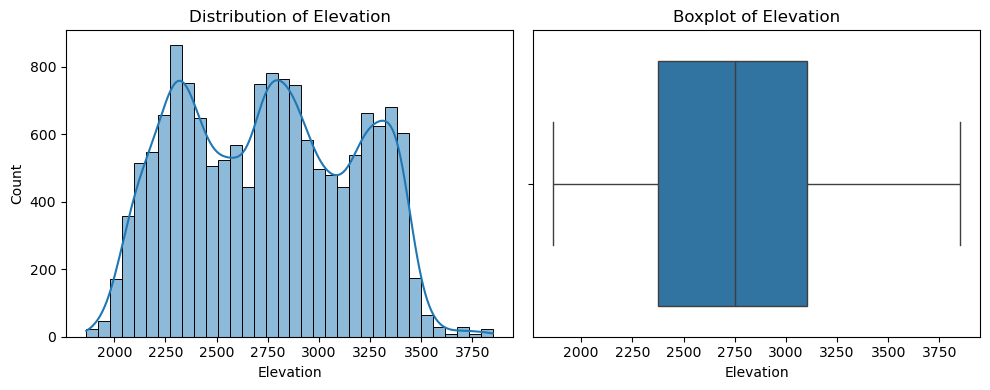

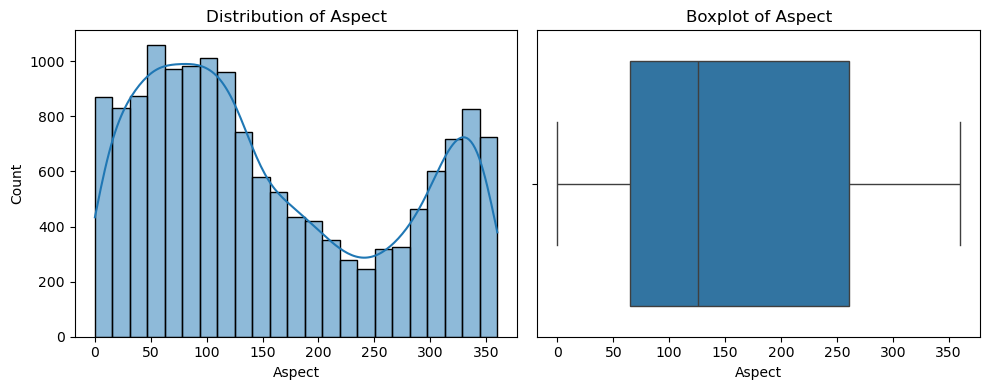

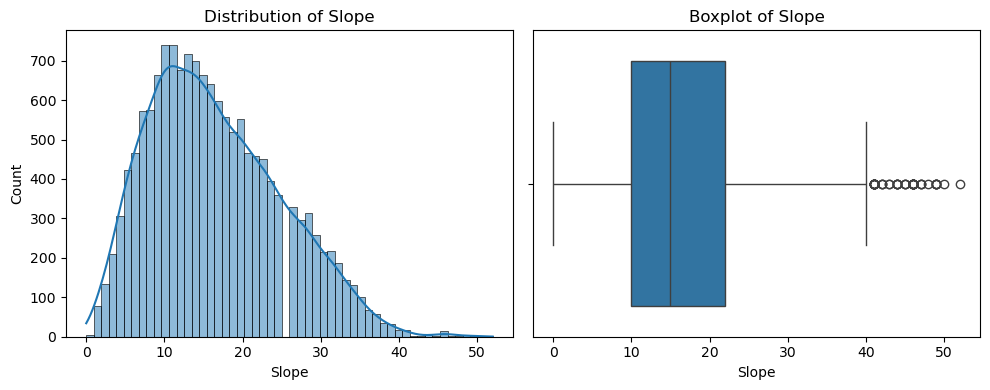

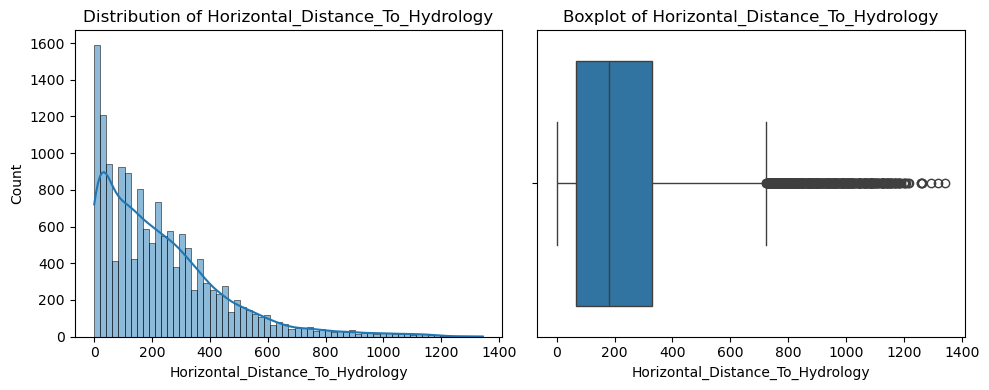

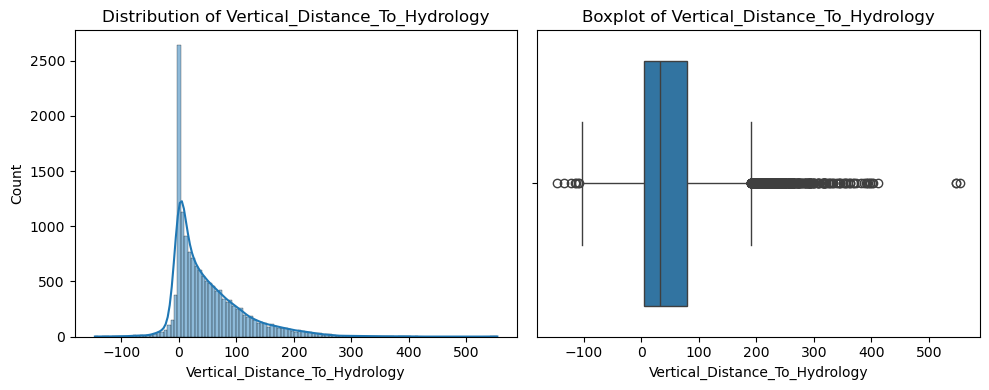

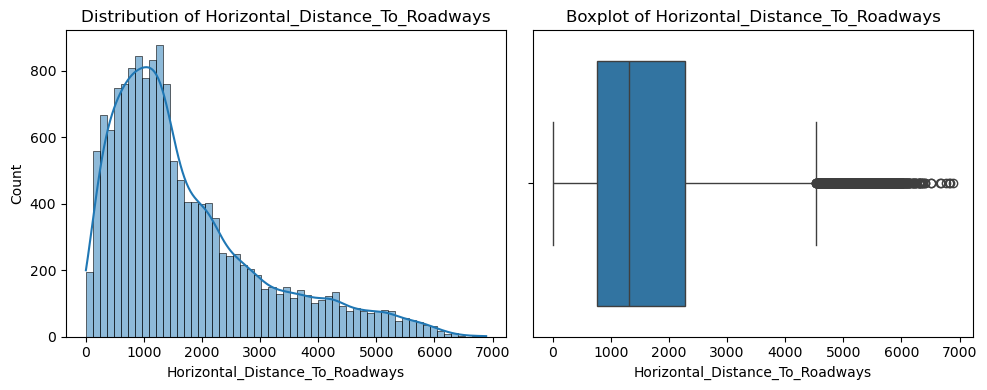

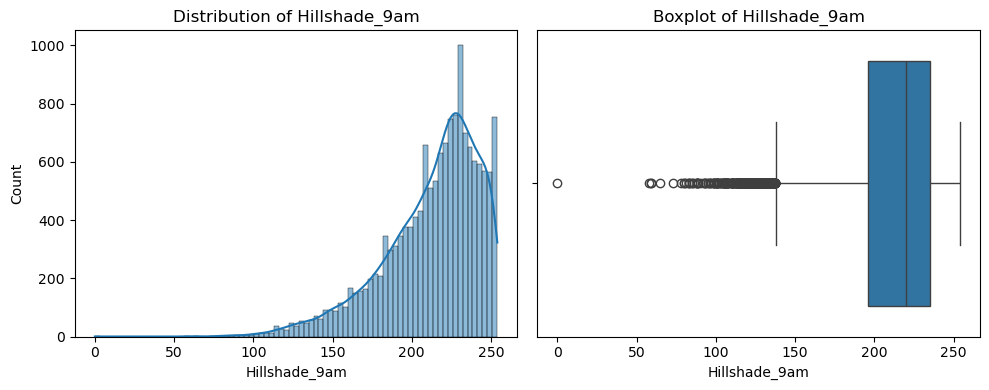

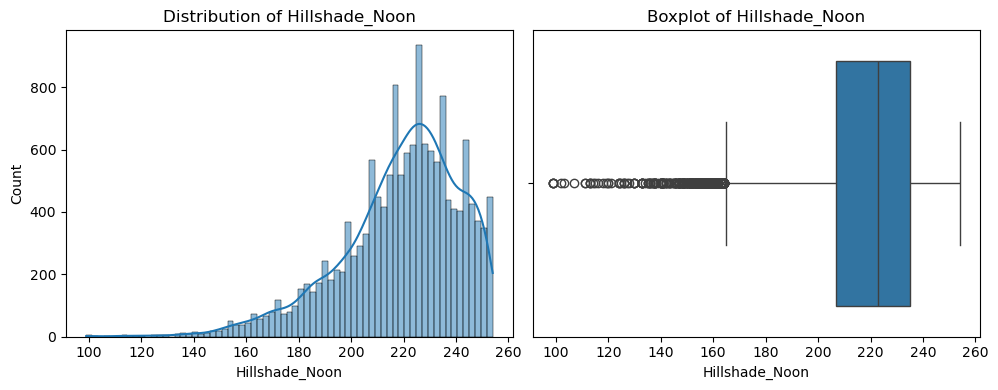

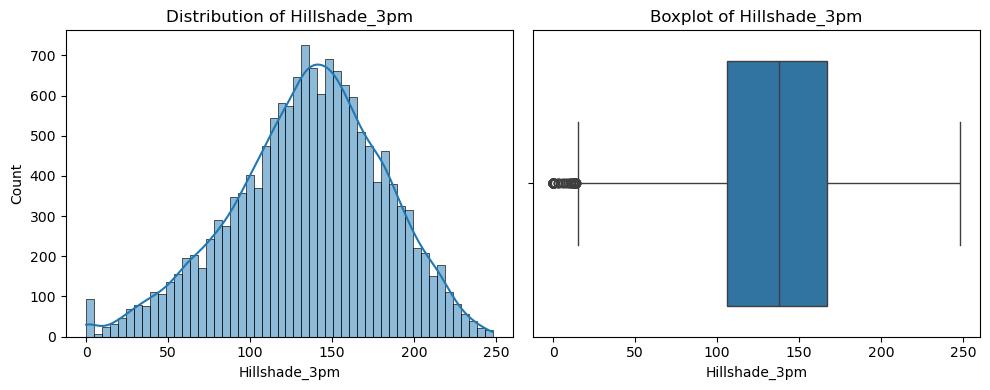

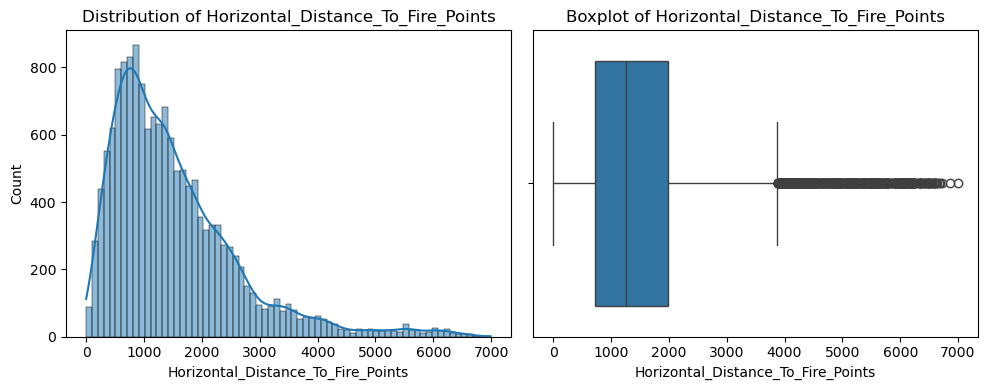

In [12]:
continuous_cols = ['Elevation', 'Aspect', 'Slope', 'Horizontal_Distance_To_Hydrology',
                    'Vertical_Distance_To_Hydrology', 'Horizontal_Distance_To_Roadways',
                    'Hillshade_9am', 'Hillshade_Noon', 'Hillshade_3pm',
                    'Horizontal_Distance_To_Fire_Points']

for col in continuous_cols:
    plt.figure(figsize=(10,4))

    plt.subplot(1,2,1)
    sns.histplot(df[col], kde=True)
    plt.title(f'Distribution of {col}')

    plt.subplot(1,2,2)
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')

    plt.tight_layout()
    plt.show()

### Insights :
- Elevation shows three separate peaks, likely because the four wilderness areas sit at different elevation ranges, and there are no outliers.
- Aspect shows peaks near 0 and 360, which actually represent similar directions since it is a circular feature measured in degrees, so this is expected and not an issue.
- Slope is right skewed, with most values between 5 and 25 degrees, and a good number of outliers on the higher, steeper side.
- Horizontal_Distance_To_Hydrology is heavily right skewed, most land is within 200 to 400 meters of water, with many outliers on the higher side going up to 1400.
- Vertical_Distance_To_Hydrology is sharply peaked near 0 and right skewed, with outliers on both the positive and negative side, the negative values are valid since water sources can sit above the land point.
- Horizontal_Distance_To_Roadways is right skewed, most values fall between 500 and 2500 meters, with outliers going as far as 7000.
- Hillshade_9am and Hillshade_Noon are both left skewed, with most values concentrated between 200 and 250, and outliers appearing on the lower side.
- Hillshade_3pm looks more evenly spread and closer to a normal distribution compared to the other two hillshade features, since the sun angle at 3pm balances out the sunlight exposure across patches.
- Horizontal_Distance_To_Fire_Points is right skewed as well, peaking around 800 to 1000 meters, with outliers on the higher side extending up to 7000.
- Overall, most distance based features (hydrology, roadways, fire points) share a similar right skewed pattern, while the hillshade features behave differently since they depend on sun angle rather than physical distance.

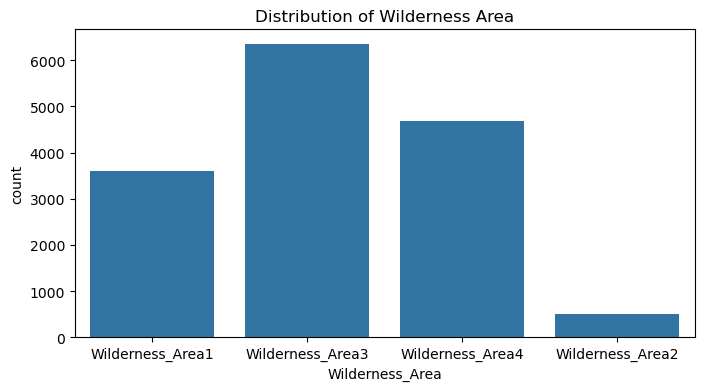

In [13]:
wilderness_cols = ['Wilderness_Area1', 'Wilderness_Area2', 'Wilderness_Area3', 'Wilderness_Area4']
df['Wilderness_Area'] = df[wilderness_cols].idxmax(axis=1)

plt.figure(figsize=(8,4))
sns.countplot(x='Wilderness_Area', data=df)
plt.title('Distribution of Wilderness Area')
plt.show()

### Insights :
- The four wilderness areas are not equally represented. Wilderness_Area3 has the most land patches (around 6300), followed by Wilderness_Area4 (around 4700) and Wilderness_Area1 (around 3600), while Wilderness_Area2 has very few, roughly 600.
- Wilderness_Area2 being this much smaller than the other three is something to keep in mind. If certain cover types only occur in Wilderness_Area2, the model will have very little data to learn that pattern from, which could hurt prediction accuracy for those specific cases.

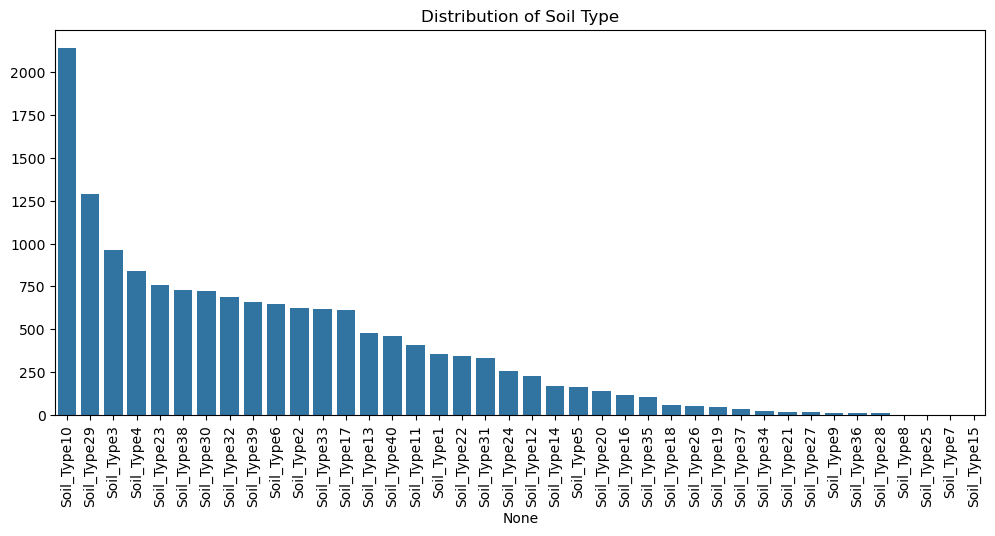

In [14]:
soil_cols = [c for c in df.columns if 'Soil_Type' in c]
soil_counts = df[soil_cols].sum().sort_values(ascending=False)

plt.figure(figsize=(12,5))
sns.barplot(x=soil_counts.index, y=soil_counts.values)
plt.xticks(rotation=90)
plt.title('Distribution of Soil Type')
plt.show()

### Insights :
- Soil_Type distribution is extremely uneven. Soil_Type10 alone has over 2000 land patches, while most other soil types have far fewer, and it drops off sharply after the first few bars.
- The right side of the chart tapers into a long tail, several soil types have only a handful of patches, and the last two, Soil_Type7 and Soil_Type15, show bars at zero, meaning they don't appear in the dataset at all. This matches what we already found earlier using isnull() and sum() checks, so it's confirmed, not a one-off reading of the chart.

## Bivariate Analysis :

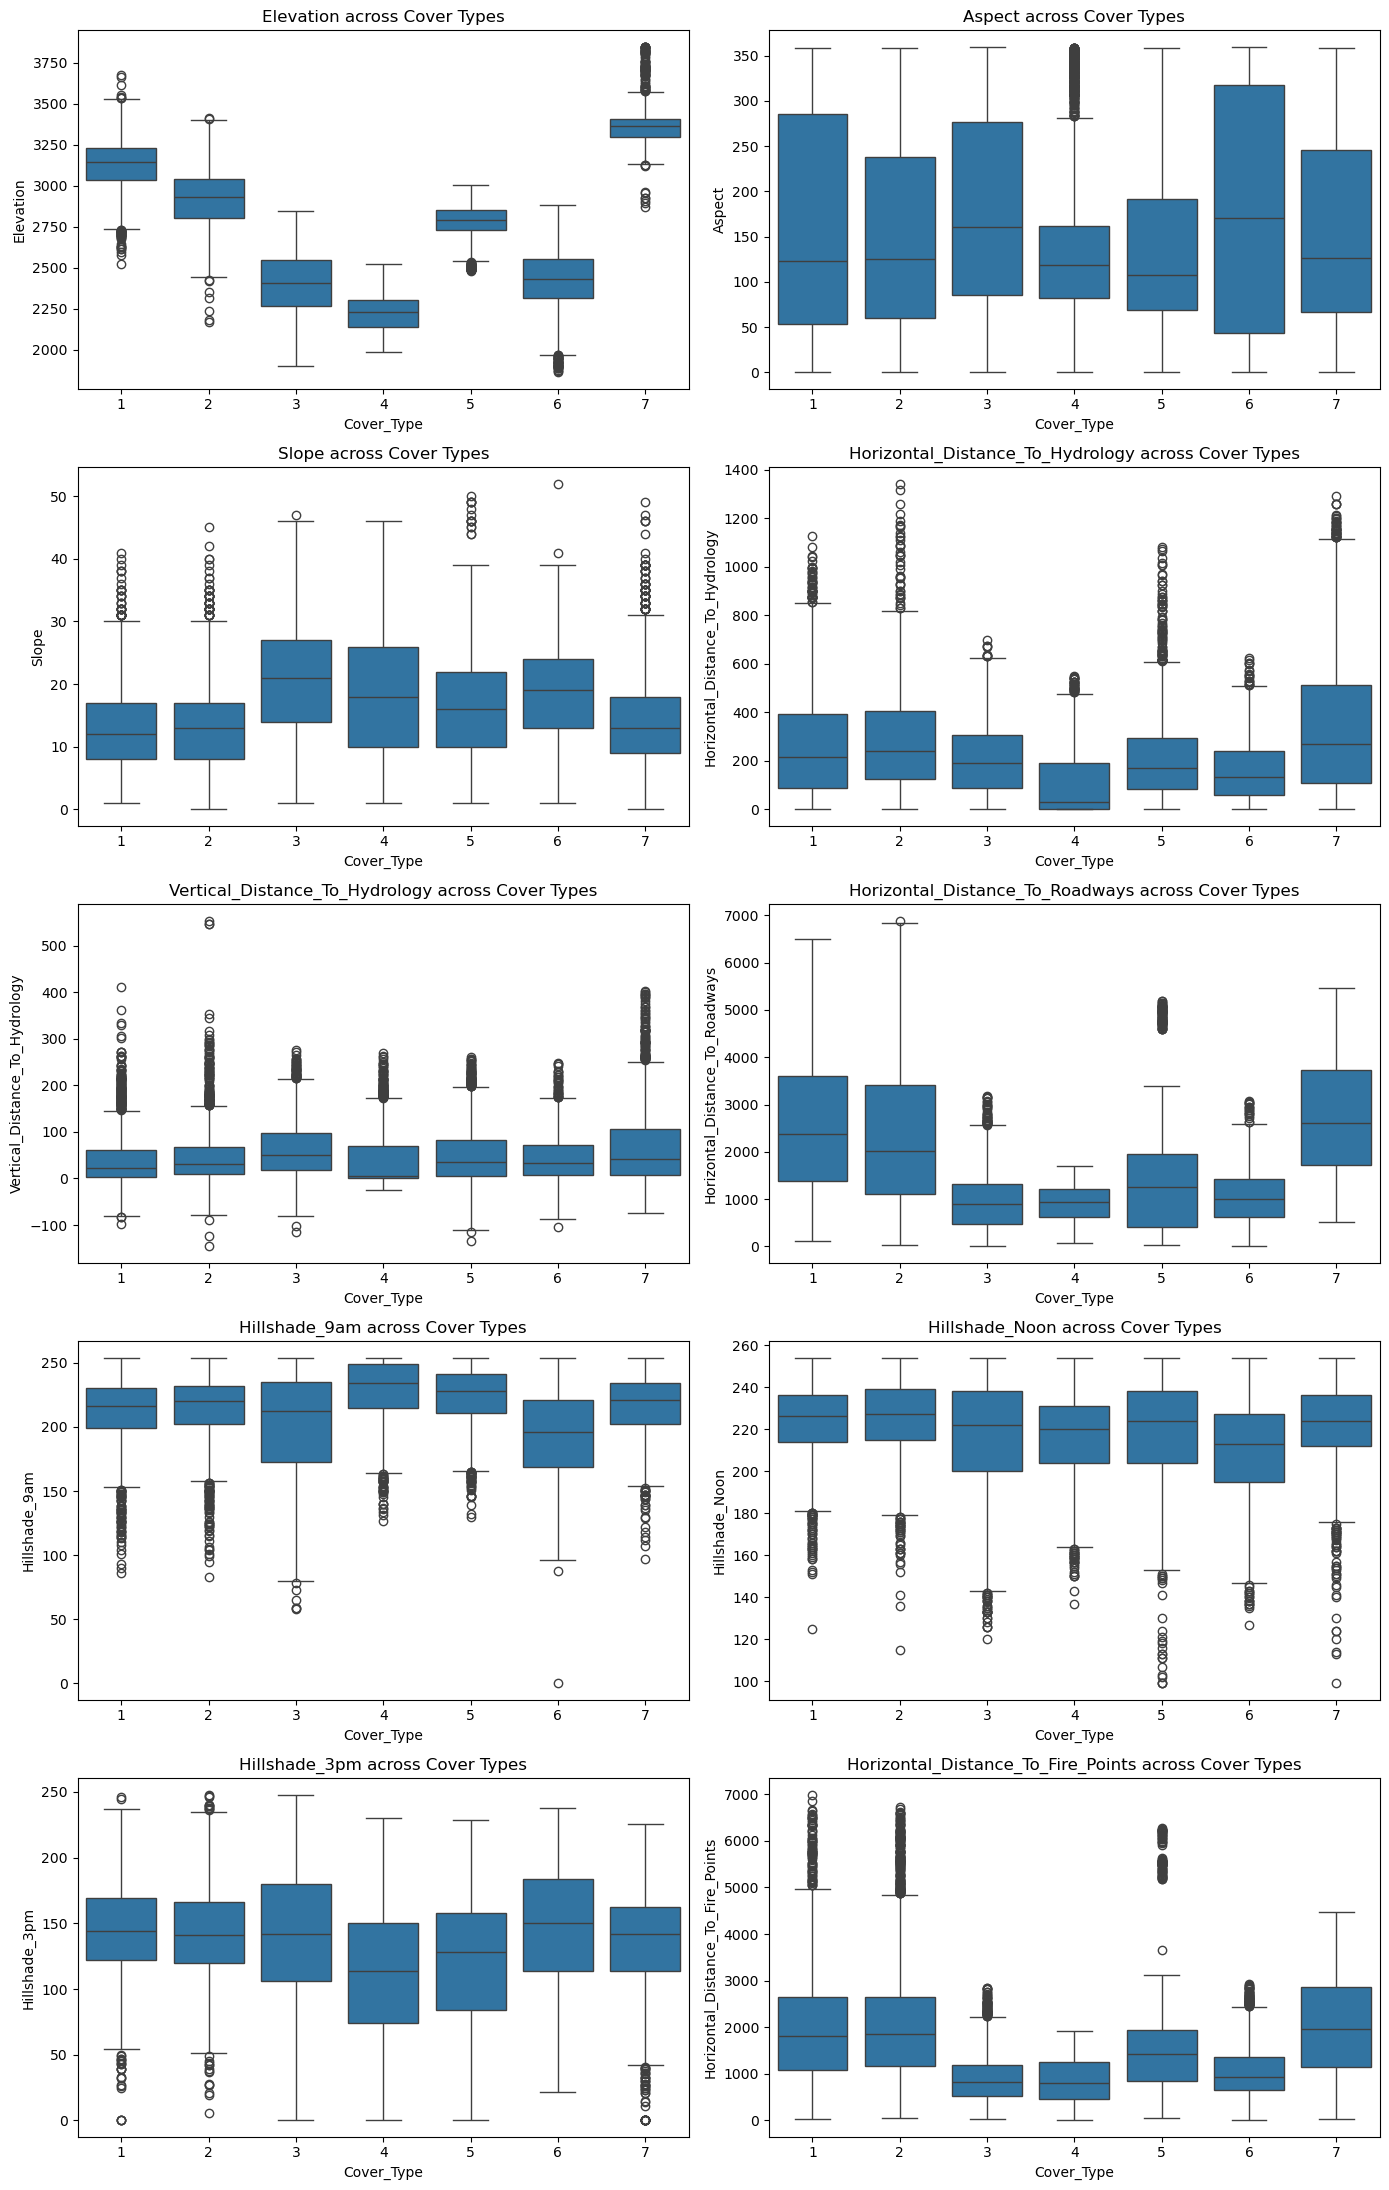

In [15]:
fig, axes = plt.subplots(5, 2, figsize=(14,22))
axes = axes.flatten()

for i, col in enumerate(continuous_cols):
    sns.boxplot(x='Cover_Type', y=col, data=df, ax=axes[i])
    axes[i].set_title(f'{col} across Cover Types')

plt.tight_layout()
plt.show()

### Insights :
- Elevation is by far the strongest separator among all the features. Cover_Type 7 sits highest (around 3100 to 3400), Cover_Type 1 is next, then 2, then 5, then 6 and 3, and Cover_Type 4 sits lowest, around 2000 to 2500 with almost no overlap with 7. This alone tells us Elevation is likely going to be one of the most important features for the model.
- Aspect shows almost no separation between cover types, the boxes are wide and heavily overlapping across all 7 classes. On its own, this feature does not look like it will help the model distinguish cover types much.
- Slope shows some difference, Cover_Type 3 and 6 have slightly higher medians than 1, 2, and 7, but the boxes overlap a lot, so the separation is weak, not strong like Elevation.
- Horizontal_Distance_To_Hydrology shows Cover_Type 4 sitting much closer to 0 than the rest, meaning that cover type tends to grow very close to water sources, while types 1, 2, and 5 tend to be farther away.
- Vertical_Distance_To_Hydrology shows Cover_Type 7 with a noticeably higher median than the others, but overlap between classes is still large.
- Horizontal_Distance_To_Roadways shows a clear pattern, Cover_Type 1 and 2 sit far from roads (median around 2000 to 2300), while Cover_Type 3, 4, and 6 are much closer to roads (median around 800 to 1000).
- Hillshade_9am and Hillshade_Noon barely separate the cover types, most classes overlap heavily, except Cover_Type 6 which sits a bit lower than the rest in both.
- Hillshade_3pm shows Cover_Type 4 on the lower end and Cover_Type 6 on the higher end, but again with heavy overlap in between.
- Horizontal_Distance_To_Fire_Points follows a similar pattern to roadways, Cover_Type 1 and 2 are farther from fire points, while 3, 4, and 6 are much closer.
- Overall, Elevation, Horizontal_Distance_To_Roadways, and Horizontal_Distance_To_Fire_Points look like the strongest predictors here, while Aspect and the Hillshade features look weak on their own. This isn't a guess, it's based directly on how much the boxes separate or overlap across cover types in these plots.

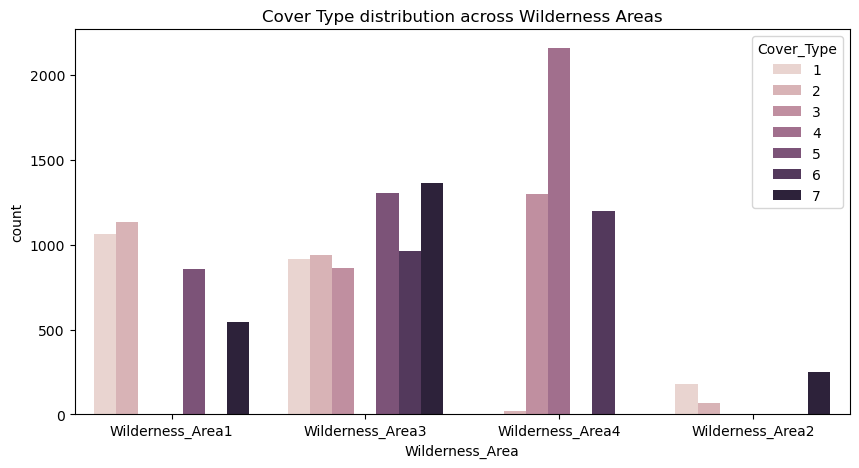

In [16]:
plt.figure(figsize=(10,5))
sns.countplot(x='Wilderness_Area', hue='Cover_Type', data=df)
plt.title('Cover Type distribution across Wilderness Areas')
plt.show()

### Insights :
- Cover Type distribution is clearly not the same across wilderness areas, certain cover types only appear in specific wilderness areas, while others are completely absent.
- Wilderness_Area1 only contains Cover_Type 1, 2, 5, and 6. Types 3, 4, and 7 do not appear here at all.
- Wilderness_Area3 contains almost every cover type (1, 2, 3, 5, 6, 7), except Cover_Type 4, which is completely absent here.
- Wilderness_Area4 is dominated by Cover_Type 4 (the tallest bar in the entire chart), and also contains Cover_Type 3 and 6 in large numbers, along with a very small number of Cover_Type 2. Types 1, 5, and 7 do not appear here at all.
- Wilderness_Area2 has very few records overall (matching what we already found in univariate analysis), and only contains Cover_Type 1, 2, and 7, in small numbers.
- This is a strong signal. Just knowing which wilderness area a land patch belongs to already rules out several cover types completely. For example, if a patch is in Wilderness_Area4, we already know it cannot be Cover_Type 1, 5, or 7. This makes Wilderness_Area a genuinely useful categorical feature for the model, not a weak one.

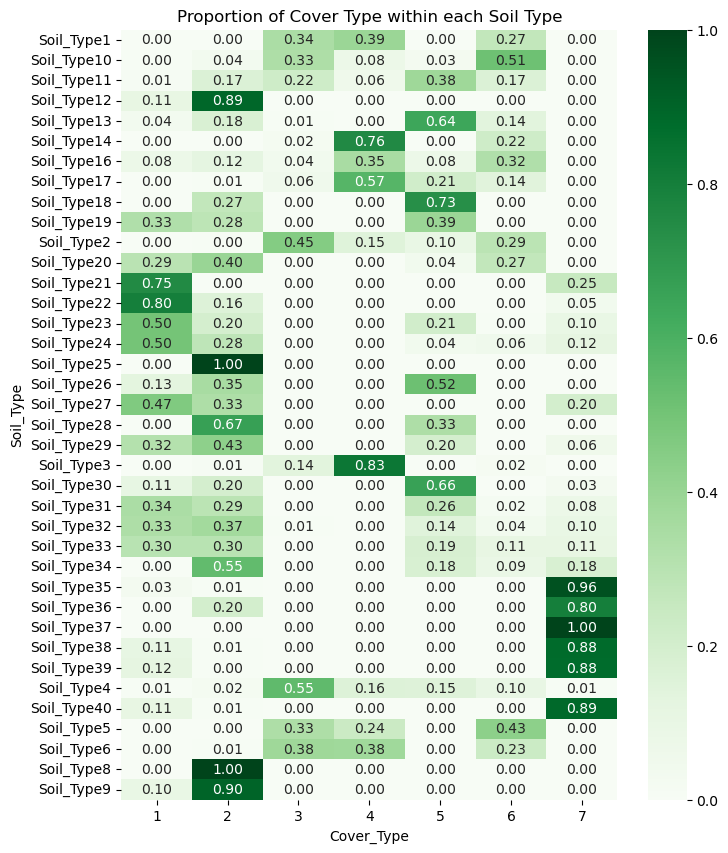

In [17]:
soil_cols = [c for c in df.columns if 'Soil_Type' in c]
df['Soil_Type'] = df[soil_cols].idxmax(axis=1)

soil_cover_crosstab = pd.crosstab(df['Soil_Type'], df['Cover_Type'], normalize='index')

plt.figure(figsize=(8,10))
sns.heatmap(soil_cover_crosstab, cmap='Greens', annot=True, fmt='.2f')
plt.title('Proportion of Cover Type within each Soil Type')
plt.xlabel('Cover_Type')
plt.ylabel('Soil_Type')
plt.show()

### Insights :
- Soil_Type is a strong predictor of Cover_Type. Many soil types show 70 percent or more of their patches belonging to a single cover type, which means knowing the soil type alone can often point directly to the cover type.
- A few soil types are almost pure indicators of one class. Soil_Type25, Soil_Type8, and Soil_Type37 each belong to a single cover type 100 percent of the time.
- Cover_Type 2 and Cover_Type 7 have the most soil types strongly linked to them, several soil types are 80 to 96 percent one or the other.
- Cover_Type 1 and Cover_Type 4 are each tied to a smaller, specific group of soil types, rather than being spread across many.
- Cover_Type 6 is the weakest of all seven classes in this table, no soil type crosses even 51 percent for it, meaning it does not have one dominant soil type the way most other cover types do, it tends to appear mixed in with other classes instead.
- A small number of soil types are genuinely mixed rather than dominant, spreading their patches across four to five different cover types with no value crossing 40 percent. These carry weaker individual predictive signal compared to the dominant ones above.

## Multivariate Analysis :

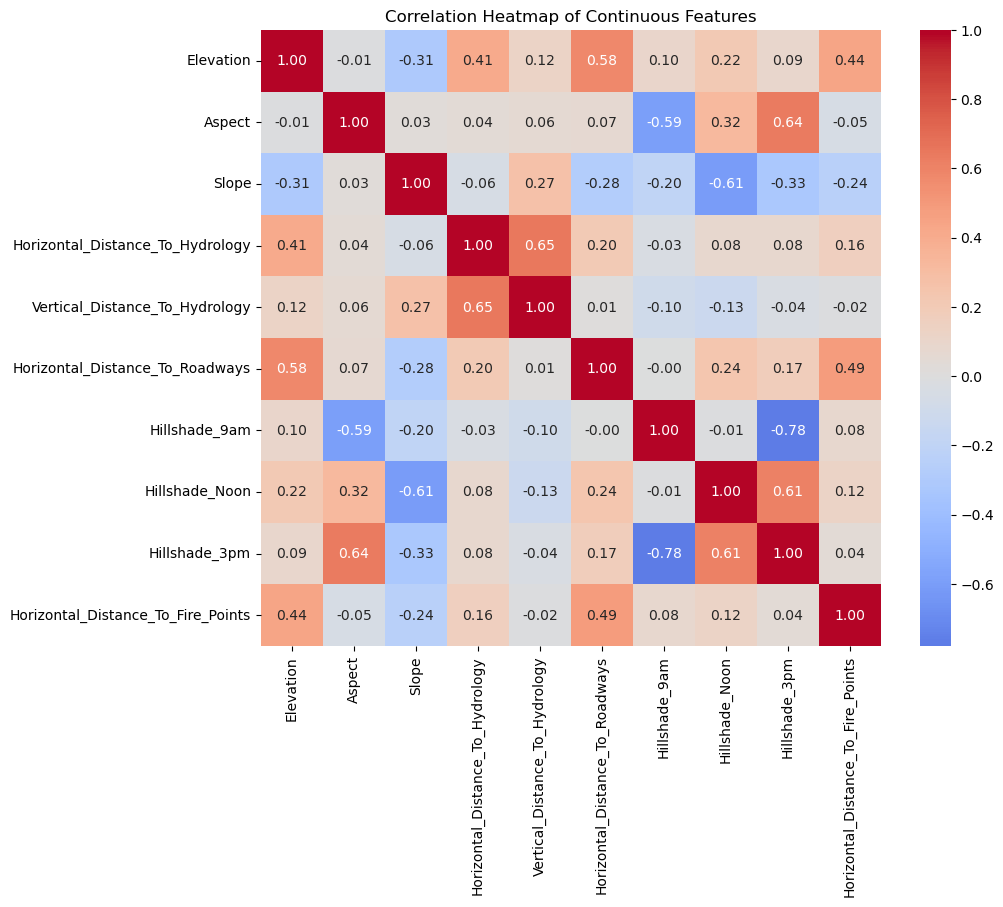

In [18]:
plt.figure(figsize=(10,8))
corr_matrix = df[continuous_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap of Continuous Features')
plt.show()

### Insights :
- The strongest correlation in the entire matrix is between Hillshade_9am and Hillshade_3pm at -0.78, meaning when morning sunlight is high, afternoon sunlight tends to be low, and vice versa. This makes physical sense, since these represent opposite ends of the day, morning and afternoon sun angles naturally move in opposite directions.
- Aspect (the compass direction a slope faces) is also fairly correlated with the same two features, -0.59 with Hillshade_9am and 0.64 with Hillshade_3pm. This is expected too, the direction a slope faces directly affects when sunlight hits it during the day.
- Horizontal_Distance_To_Hydrology and Vertical_Distance_To_Hydrology are correlated at 0.65, which makes sense since both are measuring distance to the same water sources, just in different directions (straight line versus elevation difference).
- Elevation shows a moderate positive correlation with Horizontal_Distance_To_Roadways (0.58) and Horizontal_Distance_To_Fire_Points (0.44), suggesting that higher elevation areas tend to be farther from roads and fire points, likely because roads and infrastructure are more common at lower elevations.
- Most other feature pairs show weak correlation, mostly under 0.3, which means the majority of features are carrying fairly independent information rather than repeating each other.
- No pair reaches a very high correlation like 0.9 or above, so severe multicollinearity is not a major concern in this dataset. This matters less for us anyway, since we're using tree based ensemble models for this project, which handle correlated features naturally, unlike linear models where high correlation would be a bigger problem.

# Feature Engineering :

In [19]:
df = df.drop(columns=['Id', 'Wilderness_Area', 'Soil_Type'])

In [20]:
df.shape

(15120, 55)

In [21]:
zero_var_soils = [c for c in df.columns if 'Soil_Type' in c and df[c].sum() == 0]

In [22]:
zero_var_soils

['Soil_Type7', 'Soil_Type15']

In [23]:
df = df.drop(columns=zero_var_soils)

In [24]:
df.shape

(15120, 53)

# Split the data :

In [25]:
# Separate features (X) and target (y)
X = df.drop(columns=['Cover_Type'])
y = df['Cover_Type']

In [26]:
# Train-test split
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

In [27]:
# Check shapes
print (X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(12096, 52) (3024, 52) (12096,) (3024,)


# Model Building & Evaluation :

## Random Forest :

In [28]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score

rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

In [29]:
print(confusion_matrix(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))
print("ROC-AUC:", roc_auc_score(y_test, rf.predict_proba(X_test), multi_class = "ovr"))

[[328  66   1   0   9   1  27]
 [ 77 288  12   0  36  15   4]
 [  0   2 344  20   7  59   0]
 [  0   0   5 421   0   6   0]
 [  0  11   9   0 406   6   0]
 [  0   4  41   6   1 380   0]
 [ 16   0   0   0   0   0 416]]
              precision    recall  f1-score   support

           1       0.78      0.76      0.77       432
           2       0.78      0.67      0.72       432
           3       0.83      0.80      0.82       432
           4       0.94      0.97      0.96       432
           5       0.88      0.94      0.91       432
           6       0.81      0.88      0.85       432
           7       0.93      0.96      0.95       432

    accuracy                           0.85      3024
   macro avg       0.85      0.85      0.85      3024
weighted avg       0.85      0.85      0.85      3024

ROC-AUC: 0.9826215379841923


## Extra Trees : 

In [30]:
from sklearn.ensemble import ExtraTreesClassifier

et = ExtraTreesClassifier(random_state=42)
et.fit(X_train, y_train)

y_pred_et = et.predict(X_test)

In [31]:
print (confusion_matrix(y_test, y_pred_et))
print (classification_report(y_test, y_pred_et))
print ("ROC-AUC:", roc_auc_score(y_test, et.predict_proba(X_test), multi_class = "ovr"))

[[329  69   1   0  10   2  21]
 [ 75 285  11   0  37  20   4]
 [  0   3 352  21   7  49   0]
 [  0   0   8 419   0   5   0]
 [  1  10   7   0 409   5   0]
 [  1   2  39   8   3 379   0]
 [ 14   1   0   0   0   0 417]]
              precision    recall  f1-score   support

           1       0.78      0.76      0.77       432
           2       0.77      0.66      0.71       432
           3       0.84      0.81      0.83       432
           4       0.94      0.97      0.95       432
           5       0.88      0.95      0.91       432
           6       0.82      0.88      0.85       432
           7       0.94      0.97      0.95       432

    accuracy                           0.86      3024
   macro avg       0.85      0.86      0.85      3024
weighted avg       0.85      0.86      0.85      3024

ROC-AUC: 0.9837770954789666


## Gradient Boosting :

In [32]:
from sklearn.ensemble import GradientBoostingClassifier

gb = GradientBoostingClassifier(random_state=42) 
gb.fit(X_train, y_train)

y_pred_gb = gb.predict(X_test)

In [33]:
print(confusion_matrix(y_test, y_pred_gb))
print(classification_report(y_test, y_pred_gb))
print("ROC-AUC:", roc_auc_score(y_test, gb.predict_proba(X_test), multi_class="ovr"))

[[304  71   1   0  12   2  42]
 [ 97 236  16   0  62  17   4]
 [  0   1 299  23  16  93   0]
 [  0   0  16 410   0   6   0]
 [  1  21  11   0 386  13   0]
 [  0   1  77   7  14 333   0]
 [ 20   0   0   0   0   0 412]]
              precision    recall  f1-score   support

           1       0.72      0.70      0.71       432
           2       0.72      0.55      0.62       432
           3       0.71      0.69      0.70       432
           4       0.93      0.95      0.94       432
           5       0.79      0.89      0.84       432
           6       0.72      0.77      0.74       432
           7       0.90      0.95      0.93       432

    accuracy                           0.79      3024
   macro avg       0.78      0.79      0.78      3024
weighted avg       0.78      0.79      0.78      3024

ROC-AUC: 0.9686032827911687


## AdaBoost :

In [34]:
from sklearn.ensemble import AdaBoostClassifier

ada = AdaBoostClassifier(random_state=42)
ada.fit(X_train, y_train)

y_pred_ada = ada.predict(X_test)

In [35]:
print(confusion_matrix(y_test, y_pred_ada))
print(classification_report(y_test, y_pred_ada))
print("ROC-AUC:", roc_auc_score(y_test, ada.predict_proba(X_test), multi_class="ovr"))

[[327  50   1   0   9   2  43]
 [215 121  11   0  55  24   6]
 [  0  11 187   0  27 207   0]
 [  0   0 377   0   0  55   0]
 [ 56 239   5   0 109  23   0]
 [  0  10 172   0  35 215   0]
 [291   4   0   0   0   0 137]]
              precision    recall  f1-score   support

           1       0.37      0.76      0.50       432
           2       0.28      0.28      0.28       432
           3       0.25      0.43      0.32       432
           4       0.00      0.00      0.00       432
           5       0.46      0.25      0.33       432
           6       0.41      0.50      0.45       432
           7       0.74      0.32      0.44       432

    accuracy                           0.36      3024
   macro avg       0.36      0.36      0.33      3024
weighted avg       0.36      0.36      0.33      3024

ROC-AUC: 0.8812822395118884


# Compare all the model :

In [36]:
# Comparison table across all models
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

models_results = {
    "Random Forest": (y_pred_rf, rf.predict_proba(X_test)),
    "Extra Trees": (y_pred_et, et.predict_proba(X_test)),
    "Gradient Boosting": (y_pred_gb, gb.predict_proba(X_test)),
    "AdaBoost": (y_pred_ada, ada.predict_proba(X_test))
}

summary = []
for name, (preds, proba) in models_results.items():
    summary.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, preds),
        "Precision": precision_score(y_test, preds, average="macro"),
        "Recall": recall_score(y_test, preds, average="macro"),
        "F1-score": f1_score(y_test, preds, average="macro"),
        "ROC-AUC": roc_auc_score(y_test, proba, multi_class="ovr")
    })

In [37]:
summary_df = pd.DataFrame(summary)
summary_df

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Random Forest,0.854167,0.851578,0.854167,0.851812,0.982622
1,Extra Trees,0.856481,0.853716,0.856481,0.854065,0.983777
2,Gradient Boosting,0.787037,0.783463,0.787037,0.782867,0.968603
3,AdaBoost,0.362434,0.357638,0.362434,0.329838,0.881282


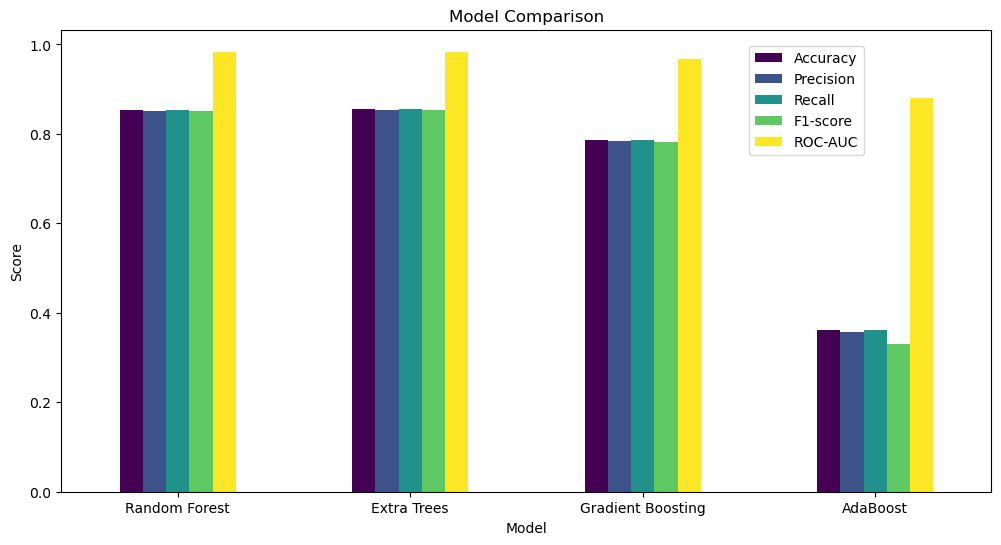

In [38]:
# Bar chart to compare all models 
summary_df.set_index("Model").plot (kind = "bar", figsize = (12,6),colormap="viridis")
plt.title("Model Comparison")
plt.ylabel("Score")
plt.xticks(rotation = 0)
plt.legend(loc="upper right", bbox_to_anchor=(0.87, 0.98))
plt.show()

# Hyper perameter tuning :

## Extra Trees tuning

In [39]:
# Extra Trees turning 
from sklearn.model_selection import RandomizedSearchCV

param_grid_et = {
    "n_estimators": [100,200,300,400],
    "max_depth": [None, 10,20,30],
    "min_samples_split": [2,5,10],
    "min_samples_leaf": [1,2,4],
    "max_features": ["sqrt", "log2"]
}

et_random = RandomizedSearchCV(
    estimator = ExtraTreesClassifier(random_state=42),
    param_distributions = param_grid_et,
    n_iter = 20,
    cv = 3,
    scoring = "accuracy",
    random_state = 42,
    n_jobs = -1
)

et_random.fit(X_train, y_train)

,estimator,ExtraTreesCla...ndom_state=42)
,param_distributions,"{'max_depth': [None, 10, ...], 'max_features': ['sqrt', 'log2'], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], ...}"
,n_iter,20
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,3
,verbose,0
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


In [40]:
# Best parameters : Extra Trees
print("Best parameters:",et_random.best_params_)

Best parameters: {'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 30}


In [41]:
# Evaluate tuned Extra Trees
best_et = et_random.best_estimator_
y_pred_et_tuned = best_et.predict(X_test)

In [42]:
print(confusion_matrix(y_test, y_pred_et_tuned))
print(classification_report(y_test, y_pred_et_tuned))
print("ROC-AUC:", roc_auc_score(y_test, best_et.predict_proba(X_test), multi_class="ovr"))

[[327  74   1   0   9   1  20]
 [ 73 289  11   0  37  18   4]
 [  0   2 355  19   7  49   0]
 [  0   0   7 418   0   7   0]
 [  0   9   9   0 410   4   0]
 [  0   2  39   9   3 379   0]
 [ 15   1   0   0   0   0 416]]
              precision    recall  f1-score   support

           1       0.79      0.76      0.77       432
           2       0.77      0.67      0.71       432
           3       0.84      0.82      0.83       432
           4       0.94      0.97      0.95       432
           5       0.88      0.95      0.91       432
           6       0.83      0.88      0.85       432
           7       0.95      0.96      0.95       432

    accuracy                           0.86      3024
   macro avg       0.86      0.86      0.86      3024
weighted avg       0.86      0.86      0.86      3024

ROC-AUC: 0.9832427258883663


## Random Forest tuning

In [43]:
# Random Forest tuning
param_grid_rf = {
    "n_estimators": [100, 200, 300, 400],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

rf_random = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_distributions=param_grid_rf,
    n_iter=20,
    cv=3,
    scoring="accuracy",
    random_state=42,
    n_jobs=-1
)

rf_random.fit(X_train, y_train)

,estimator,RandomForestC...ndom_state=42)
,param_distributions,"{'max_depth': [None, 10, ...], 'max_features': ['sqrt', 'log2'], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], ...}"
,n_iter,20
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,3
,verbose,0
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


In [44]:
# Best parameters : Random Forest
print("Best parameters:",rf_random.best_params_)

Best parameters: {'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 30}


In [45]:
# Evaluate tuned Random Forest
best_rf = rf_random.best_estimator_
y_pred_rf_tuned = best_rf.predict(X_test)

In [46]:
print(confusion_matrix(y_test, y_pred_rf_tuned))
print(classification_report(y_test, y_pred_rf_tuned))
print("ROC-AUC:", roc_auc_score(y_test, best_rf.predict_proba(X_test), multi_class="ovr"))

[[325  64   1   0  12   2  28]
 [ 73 289  12   0  36  18   4]
 [  0   2 342  20   9  59   0]
 [  0   0   5 424   0   3   0]
 [  0   9  10   0 408   5   0]
 [  0   3  40   6   2 381   0]
 [ 14   0   0   0   0   0 418]]
              precision    recall  f1-score   support

           1       0.79      0.75      0.77       432
           2       0.79      0.67      0.72       432
           3       0.83      0.79      0.81       432
           4       0.94      0.98      0.96       432
           5       0.87      0.94      0.91       432
           6       0.81      0.88      0.85       432
           7       0.93      0.97      0.95       432

    accuracy                           0.86      3024
   macro avg       0.85      0.86      0.85      3024
weighted avg       0.85      0.86      0.85      3024

ROC-AUC: 0.9825413538400614


In [47]:
# Add tuned Extra Trees to the comparison
summary_df.loc[len(summary_df)] = {
    "Model": "Extra Trees (Tuned)",
    "Accuracy": accuracy_score(y_test, y_pred_et_tuned),
    "Precision": precision_score(y_test, y_pred_et_tuned, average="macro"),
    "Recall": recall_score(y_test, y_pred_et_tuned, average="macro"),
    "F1-score": f1_score(y_test, y_pred_et_tuned, average="macro"),
    "ROC-AUC": roc_auc_score(y_test, best_et.predict_proba(X_test), multi_class="ovr")
}

# Add tuned Random Forest to the comparison
summary_df.loc[len(summary_df)] = {
    "Model": "Random Forest (Tuned)",
    "Accuracy": accuracy_score(y_test, y_pred_rf_tuned),
    "Precision": precision_score(y_test, y_pred_rf_tuned, average="macro"),
    "Recall": recall_score(y_test, y_pred_rf_tuned, average="macro"),
    "F1-score": f1_score(y_test, y_pred_rf_tuned, average="macro"),
    "ROC-AUC": roc_auc_score(y_test, best_rf.predict_proba(X_test), multi_class="ovr")
}
summary_df

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Random Forest,0.854167,0.851578,0.854167,0.851812,0.982622
1,Extra Trees,0.856481,0.853716,0.856481,0.854065,0.983777
2,Gradient Boosting,0.787037,0.783463,0.787037,0.782867,0.968603
3,AdaBoost,0.362434,0.357638,0.362434,0.329838,0.881282
4,Extra Trees (Tuned),0.857804,0.855111,0.857804,0.855586,0.983243
5,Random Forest (Tuned),0.855489,0.852760,0.855489,0.852791,0.982541


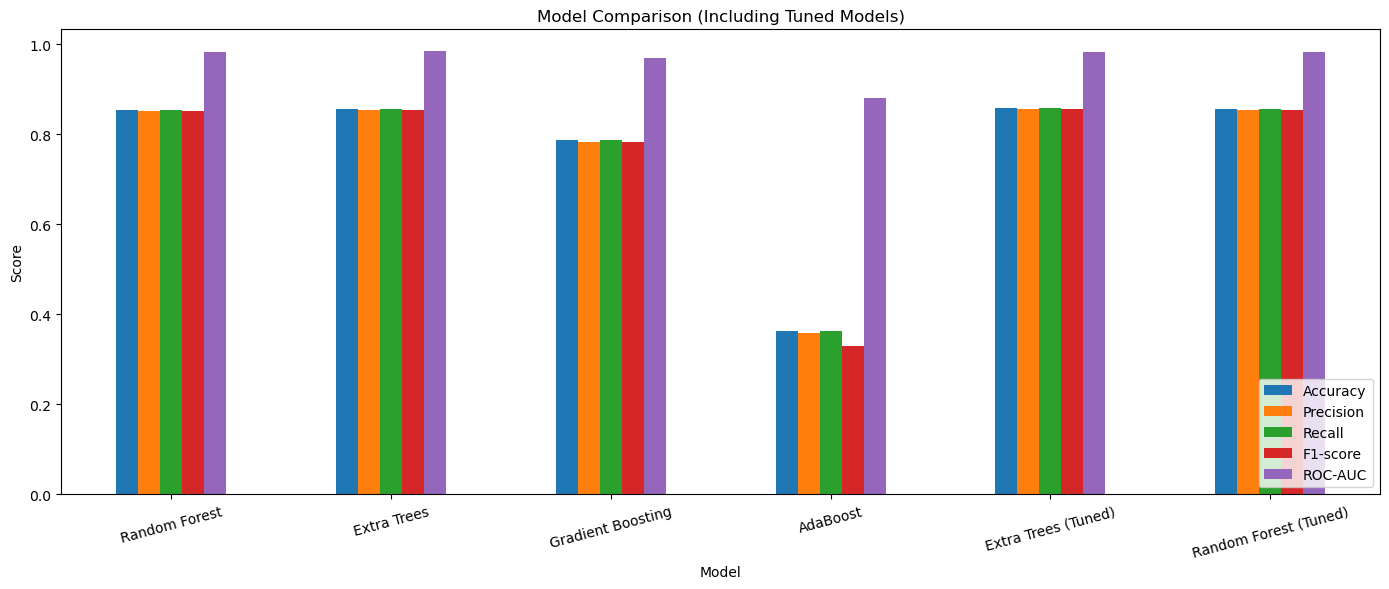

In [48]:
summary_df.set_index("Model").plot(kind="bar", figsize=(14,6))
plt.title("Model Comparison (Including Tuned Models)")
plt.ylabel("Score")
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# Feature Importance :

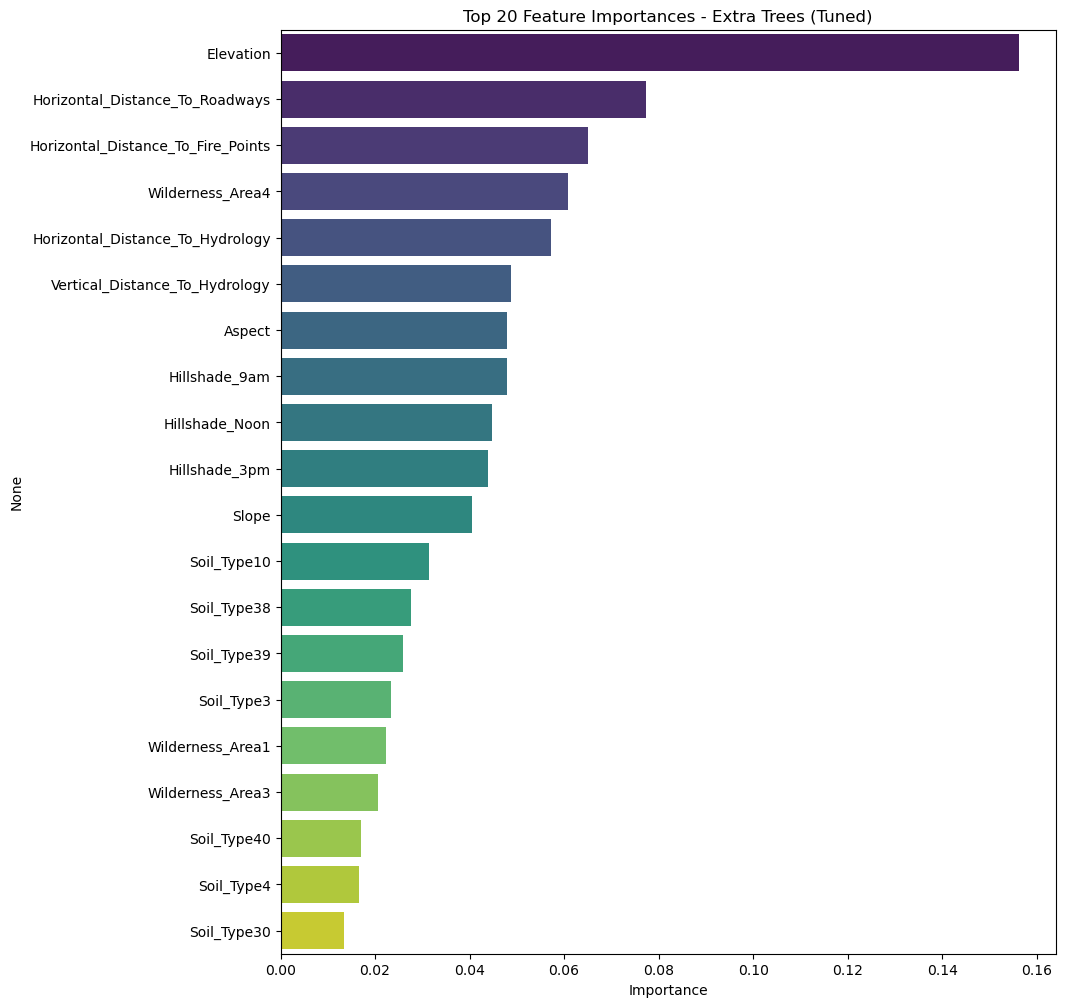

In [49]:
# Feature importance from tuned Extra Trees
importances = pd.Series(best_et.feature_importances_, index=X_train.columns)
importances = importances.sort_values(ascending=False)

plt.figure(figsize=(10,12))
sns.barplot(x=importances.values[:20], y=importances.index[:20],palette='viridis')
plt.title('Top 20 Feature Importances - Extra Trees (Tuned)')
plt.xlabel('Importance')
plt.show()

## Insights :
- Elevation is the most important feature by far, its bar is much longer than every other feature. This matches what we saw in bivariate analysis, Elevation was the feature that separated cover types the most clearly.
- Horizontal_Distance_To_Roadways and Horizontal_Distance_To_Fire_Points come next, in 2nd and 3rd place. This also matches bivariate analysis, where Cover_Type 1 and 2 were far from roads and fire points, while 3, 4, and 6 were close.
- Wilderness_Area4 is in 4th place, higher than any other single Wilderness_Area or Soil_Type column. This confirms Wilderness_Area is a useful feature, especially since Wilderness_Area4 was almost fully linked to Cover_Type 4 earlier.
- Both hydrology distance features are in the top 6, which fits with what we saw before, they were correlated with each other and showed a clear pattern for Cover_Type 4.
- Aspect and the three Hillshade features sit in the middle of the top 20. On their own, in bivariate analysis, they looked weak. But here they rank higher than expected, this shows the model is using them together with other features to find useful patterns, even if they didn't look strong alone.
- Slope ranks just below the Hillshade features, which matches the moderate difference it showed between cover types earlier.
- Some individual Soil_Type columns and Wilderness_Area1, Wilderness_Area3 appear lower on the list than expected. This is because each soil type is its own separate column, so even a soil type that is a near perfect predictor gets a small importance score on its own, since it is only compared column by column, not as one combined group.

# Model Comparison Report :

* Six models were built and evaluated for this project, four baseline ensemble models and two tuned versions of the strongest baselines. Since Cover_Type is a balanced, 7-class target, all metrics (Precision, Recall, F1-score) were calculated using macro averaging, which treats every class equally regardless of size.

### Summary Table

| Model                  | Accuracy | Precision | Recall | F1-score | ROC-AUC |
|--------------------------|----------|-----------|--------|----------|---------|
| Random Forest             | 0.8542   | 0.8516    | 0.8542 | 0.8518   | 0.9826  |
| Extra Trees                | 0.8565   | 0.8537    | 0.8565 | 0.8541   | 0.9838  |
| Gradient Boosting          | 0.7870   | 0.7835    | 0.7870 | 0.7829   | 0.9686  |
| AdaBoost                   | 0.3624   | 0.3576    | 0.3624 | 0.3298   | 0.8813  |
| Extra Trees (Tuned)        | 0.8578   | 0.8551    | 0.8578 | 0.8556   | 0.9832  |
| Random Forest (Tuned)      | 0.8555   | 0.8528    | 0.8555 | 0.8528   | 0.9825  |

### Observations

- Random Forest and Extra Trees were the two strongest baseline models, both scoring close to 85 to 86 percent accuracy and above 0.98 ROC-AUC, well ahead of the other two models.
- Gradient Boosting performed noticeably weaker as a baseline, around 6 to 7 percent lower accuracy than the two bagging models, without any tuning applied.
- AdaBoost performed poorly on this dataset, only 36 percent accuracy, barely better than random guessing for a 7-class problem. This is mainly because AdaBoost's default base learner is a decision stump (a tree with only one split), which is too simple to capture the complex, overlapping patterns in this dataset.
- Tuning gave only a small improvement for both models. Extra Trees improved from 0.8565 to 0.8578 accuracy, and Random Forest improved from 0.8542 to 0.8555. Both models also landed on the exact same best parameters (n_estimators=100, max_depth=30, min_samples_split=2, min_samples_leaf=1, max_features='sqrt'), since both searches used the same random state and parameter grid.
- ROC-AUC actually dropped very slightly after tuning for both models, a small, expected variation, not a meaningful decline.

### Final Model Selection

**Extra Trees (Tuned)** is selected as the final model for this project, with an accuracy of 85.78 percent, macro F1-score of 0.8556, and ROC-AUC of 0.9832, the highest overall performance among all six models tested. Feature importance from this final model also confirmed several patterns already found during EDA, particularly the strong influence of Elevation, distance based features, and Wilderness_Area.

# Report on Challenges Faced :

1. Binary to multiclass adaptation
Since this project has 7 target classes instead of 2, standard metrics (precision, recall, f1, ROC-AUC) needed average='macro' and multi_class='ovr' to work correctly.

2. Visualizing high dimensional categorical data
Soil_Type had 40 one-hot encoded columns, too many for a standard countplot to stay readable. A proportion based heatmap (pd.crosstab with normalize='index') was used instead to compare all soil types fairly.

3. AdaBoost performing poorly
AdaBoost scored only 36 percent accuracy, close to random guessing. This was traced to its default base learner being a decision stump (max_depth=1), too simple for this dataset's complexity.

4. Minimal improvement from tuning
RandomizedSearchCV gave less than 1.5 percent accuracy improvement for both Random Forest and Extra Trees, showing both models were already close to their performance ceiling with default settings.

5. Removing redundant columns before modeling
Temporary columns created during EDA for plotting (Wilderness_Area, Soil_Type) had to be dropped before modeling, since they duplicated information already present in the one-hot encoded columns.

# Conclusion :

- This project analyzed cartographic and environmental data to predict forest cover type across four wilderness areas in Roosevelt National Forest, Colorado. Exploratory data analysis showed the data was clean, with no missing values or duplicates, and a perfectly balanced target across all 7 cover types. Elevation, Wilderness_Area, and several Soil_Type categories emerged as strong predictors during bivariate analysis, while features like Aspect and Hillshade showed weak separation individually.

- Four ensemble models were tested as baselines, Random Forest, Extra Trees, Gradient Boosting, and AdaBoost. Random Forest and Extra Trees performed the best, both above 85 percent accuracy and 0.98 ROC-AUC, while AdaBoost performed poorly (36 percent accuracy) due to its default weak learner being unsuitable for this dataset's complexity. Hyperparameter tuning using RandomizedSearchCV was applied to both Random Forest and Extra Trees, giving a small improvement.

**Extra Trees (Tuned)** was selected as the final model, achieving 85.78 percent accuracy, a macro F1-score of 0.8556, and a ROC-AUC of 0.9832. Feature importance from this final model confirmed the EDA findings, Elevation was the most influential feature by a large margin, followed by distance based features and Wilderness_Area, validating that the patterns observed during exploratory analysis translated directly into what the model actually learned.

# Model save :

In [50]:
import joblib
joblib.dump(best_et,'forest_cover_extra_trees_tuned.pkl')

['forest_cover_extra_trees_tuned.pkl']

--- Thank you ---